# Used Car Price Prediction in Vietnam
## Xây Dựng Hệ Thống Machine Learning Định Giá Ô Tô Đã Qua Sử Dụng Toàn Diện & Đánh Giá Độ Bền Khoa Học
**AI Club End-Training Mini Project**

---

### Phần 1 — Project Overview (Tổng Quan Dự Án)

#### 1.1. Bài toán và Mục tiêu kinh doanh
Thị trường mua bán ô tô đã qua sử dụng tại Việt Nam là một thị trường thứ cấp phi tập trung, phân mảnh và có mức độ **bất cân xứng thông tin (Information Asymmetry)** rất cao giữa các salon chuyên nghiệp và người mua cá nhân. Người tiêu dùng thường gặp khó khăn trong việc định lượng giá trị thực của một chiếc xe dựa trên tình trạng lăn bánh, tuổi đời và trang bị kỹ thuật.

Mục tiêu của dự án là xây dựng một hệ thống Machine Learning có khả năng:
- **Dự đoán giá chào bán hợp lý (`price_vnd`)** của ô tô đã qua sử dụng tại Việt Nam từ 15 đặc trưng kỹ thuật, vận hành và phân khúc thị trường.
- Đóng vai trò như một **mỏ neo định giá khách quan (Objective Price Anchor)** phục vụ người mua cá nhân và chuyên viên thẩm định.
- Thiết lập một quy trình dữ liệu tất định, tuân thủ nghiêm ngặt nguyên tắc **Zero Data Leakage**, và kiểm định độ bền mô hình trước hiện tượng tin đăng trùng lặp (Cross-posting duplicates).

#### 1.2. Định nghĩa bài toán Machine Learning
- **Dạng bài toán**: Supervised Learning (Học có giám sát) — **Tabular Regression (Hồi quy dữ liệu bảng)**.
- **Biến mục tiêu (Target)**: `price_vnd` — Giá rao bán chính thức của phương tiện tính theo Việt Nam Đồng (VND).
- **Hàm mục tiêu tối ưu**: Huấn luyện trên không gian logarit tự nhiên $y_{\text{log}} = \ln(\text{price\_vnd})$ nhằm cực tiểu hóa sai số bình phương trung bình trên thang log (MSE on log scale), tương đương với việc tối ưu hóa **sai số tỷ đối tương đối (Relative Percentage Error)** thay vì giá trị tiền tệ tuyệt đối.

#### 1.3. Phân biệt Giá niêm yết (Asking Price) và Giá giao dịch thực tế (Transaction Price)
- **Asking Price (Giá chào bán/niêm yết)**: Là giá hiển thị công khai trên các tin đăng trực tuyến do người bán kỳ vọng. Dữ liệu trong đồ án này phản ánh giá chào bán.
- **Transaction Price (Giá giao dịch thực tế)**: Là số tiền thực tế được chuyển nhượng và công chứng sau khi hai bên đã thương lượng. Tại Việt Nam, biên độ mặc cả (Negotiation Margin) thông thường dao động từ **2% đến 5%** giá trị xe.
- Do đó, một mô hình đạt sai số trung vị tương đối (**MdAPE $\approx 4.29\%$**) nằm trọn vẹn trong biên độ mặc cả thị trường, mang lại giá trị ứng dụng thực tiễn rất cao.

#### 1.4. Phạm vi & Giới hạn nghiên cứu
- **Tập đối tượng trọng tâm (Cohort A)**: Các xe sản xuất từ năm 2015 đến 2023 (xe $\le 8$ năm tuổi), chiếm hơn $85\%$ thanh khoản thị trường xe cũ đương đại.
- **Giới hạn nhận thức**: Dữ liệu thu thập từ các sàn xe trực tuyến không công khai số khung (VIN) hoặc biển số xe vì lý do quyền riêng tư. Do đó, việc gom nhóm trùng lặp được thực hiện qua đối soát thông số và nội dung bài đăng.


---
### Phần 2 — Environment & Data Loading (Thiết Lập Môi Trường & Tiếp Nhận Dữ Liệu)

Trong phần này, chúng ta kiểm tra môi trường thực thi, import các thư viện khoa học dữ liệu chuẩn mực, thiết lập đường dẫn tương đối độc lập với hệ điều hành và tiếp nhận dữ liệu.


In [1]:
import os
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

# Thiết lập đường dẫn gốc dự án (Project Root)
# Tự động nhận diện thư mục gốc dù notebook chạy từ thư mục root hay thư mục notebooks/
CURRENT_DIR = Path.cwd()
if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Thêm PROJECT_ROOT vào sys.path để import các module từ src/
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project Root: {PROJECT_ROOT}")
print(f"Python executable: {sys.executable}")
print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Scikit-Learn version: {sklearn.__version__}")
print(f"Joblib version: {joblib.__version__}")

# Thiết lập giao diện biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.figsize"] = (10, 6)


Project Root: D:\ai-club-end-training
Python executable: C:\Users\DELL\AppData\Local\Programs\Python\Python311\python.exe
Python version: 3.11.9
NumPy version: 2.4.6
Pandas version: 3.0.6
Scikit-Learn version: 1.9.1
Joblib version: 1.6.0


#### Tải dữ liệu từ đường dẫn tương đối (Data Ingestion)
Quy trình sẽ tự động kiểm tra sự tồn tại của tệp dữ liệu thô cục bộ (`car_detail.csv`). Nếu tệp thô chưa được tải về (do lý do bản quyền phân phối trên GitHub public repo), hệ thống sẽ tự động sử dụng tệp dữ liệu sạch đã lưu hoặc tệp dữ liệu mẫu `synthetic_demo_data.csv` kèm hướng dẫn chi tiết.


In [2]:
RAW_DETAIL_PATH = PROJECT_ROOT / "data" / "raw" / "external" / "mquaan_car_price" / "car_detail.csv"
CLEAN_PHASE5_PATH = PROJECT_ROOT / "data" / "processed" / "cars_clean_phase5.csv"
DEMO_PATH = PROJECT_ROOT / "data" / "synthetic_demo_data.csv"

raw_df = None
data_mode = None

if RAW_DETAIL_PATH.exists():
    print(f"[THÀNH CÔNG] Tìm thấy tệp dữ liệu thô tại: {RAW_DETAIL_PATH.relative_to(PROJECT_ROOT)}")
    raw_df = pd.read_csv(RAW_DETAIL_PATH)
    data_mode = "RAW_ORIGINAL"
    print(f"Kích thước dữ liệu thô: {raw_df.shape[0]:,} dòng x {raw_df.shape[1]} cột")
elif CLEAN_PHASE5_PATH.exists():
    print(f"[THÔNG BÁO] Tệp thô không có sẵn. Nạp tệp đã làm sạch Phase 5 tại: {CLEAN_PHASE5_PATH.relative_to(PROJECT_ROOT)}")
    raw_df = pd.read_csv(CLEAN_PHASE5_PATH)
    data_mode = "CLEANED_PHASE5"
    print(f"Kích thước dữ liệu Cohort A: {raw_df.shape[0]:,} dòng x {raw_df.shape[1]} cột")
elif DEMO_PATH.exists():
    print(f"[CẢNH BÁO] Không tìm thấy dữ liệu thật. Nạp tệp mẫu độc lập tại: {DEMO_PATH.relative_to(PROJECT_ROOT)}")
    raw_df = pd.read_csv(DEMO_PATH)
    data_mode = "SYNTHETIC_DEMO"
    print(f"Kích thước dữ liệu demo: {raw_df.shape[0]:,} dòng x {raw_df.shape[1]} cột")
else:
    raise FileNotFoundError(
        "Không tìm thấy bất kỳ nguồn dữ liệu nào. Vui lòng tham khảo 'data/DATA_README.md' "
        "để đặt tệp dữ liệu vào đúng cấu trúc thư mục."
    )

# Xem qua các cột và kiểu dữ liệu
print(f"\nTrạng thái nguồn dữ liệu: {data_mode}")
display_cols = list(raw_df.columns)[:10]
print(f"10 cột đầu tiên: {display_cols}")
print(f"Số lượng giá trị null trên toàn bộ dataset: {raw_df.isnull().sum().sum():,}")
raw_df.head(3)


[THÀNH CÔNG] Tìm thấy tệp dữ liệu thô tại: data\raw\external\mquaan_car_price\car_detail.csv


Kích thước dữ liệu thô: 30,652 dòng x 21 cột

Trạng thái nguồn dữ liệu: RAW_ORIGINAL
10 cột đầu tiên: ['Mã tin', 'Xuất xứ', 'Tình trạng', 'Dòng xe', 'Số Km đã đi', 'Màu ngoại thất', 'Màu nội thất', 'Số cửa', 'Số chỗ ngồi', 'Động cơ']
Số lượng giá trị null trên toàn bộ dataset: 23,939


,Mã tin,Xuất xứ,Tình trạng,Dòng xe,Số Km đã đi,Màu ngoại thất,Màu nội thất,Số cửa,Số chỗ ngồi,Động cơ,...,Hộp số,Dẫn động,Tiêu thụ nhiên liệu,Mô tả,Hãng,Grade,Năm sản xuất,Tên xe,Giá,URL
0,17042,Lắp ráp trong nước,Xe mới,Truck,0 Km,Trắng,Ghi,2 cửa,2 chỗ,Xăng\t1.0 L,...,Số tay,RFD - Dẫn động cầu sau,L/100Km,Super Carry Truck 5 tạ thùng lửng được trang b...,Suzuki,Super Carry Truck,2022.0,Xe Suzuki Super Carry Truck 1.0 MT 2022,249 Triệu,https://bonbanh.com/xe-suzuki-super_carry_truc...
1,53794,Nhập khẩu,Xe mới,SUV,0 Km,Đen,Đen,5 cửa,7 chỗ,Xăng\t3.4 L,...,Số tự động,AWD - 4 bánh toàn thời gian,10\tL/100Km,"Toyota LANDCRUISER 300 mới, nhập khẩu Nhật Bản...",Toyota,Land Cruiser,2022.0,Xe Toyota Land Cruiser 3.5 V6 2022,4 Tỷ 286 Triệu,https://bonbanh.com/xe-toyota-land_cruiser-3.5...
2,73954,Lắp ráp trong nước,Xe mới,Crossover,0 Km,Bạc,Nâu,5 cửa,8 chỗ,Xăng\t2.0 L,...,Số tự động,RFD - Dẫn động cầu sau,L/100Km,**Hỗ trợ lệ phí trước bạ trị giá 15 triệu đồng...,Toyota,Innova,2023.0,Xe Toyota Innova G 2.0 AT 2023,885 Triệu,https://bonbanh.com/xe-toyota-innova-g-2.0-at-...


---
### Phần 3 — Exploratory Data Analysis (Khám Phá Dữ Liệu Chuyên Sâu)

Trong phần này, chúng ta phân tích các đặc tính thống kê cơ bản của thị trường xe cũ Việt Nam:
1. **Phân phối biến mục tiêu Giá (`price_vnd`)**: So sánh giữa Mean, Median, Quartiles và xác định mức độ lệch phải (Right-skewness).
2. **Hiệu ứng Biến đổi Logarit**: Chứng minh lý do $\ln(\text{price\_vnd})$ đưa dữ liệu về phân phối chuẩn đối xứng.
3. **Phân tích số km lăn bánh (ODO)**: Hiện tượng xe mới $0\text{ km}$ tại showroom và các giá trị ODO bất thường.
4. **Phân tích phân khúc & Thương hiệu**: Sự phân hóa giữa thương hiệu xe phổ thông (Toyota, Hyundai, Kia, Mazda) và thương hiệu xe sang (Mercedes-Benz, Lexus, BMW).


THỐNG KÊ MÔ TẢ BIẾN MỤC TIÊU GIÁ XE (price_vnd)
Số lượng bản ghi có giá:     30,652
Giá nhỏ nhất (Min):           18,000,000 VND (18.0 Triệu)
Phân vị 25% (Q1):             410,000,000 VND (410.0 Triệu)
Giá trung vị (Median):        620,000,000 VND (620.0 Triệu)
Giá trung bình (Mean):        1,180,744,682 VND (1180.7 Triệu)
Phân vị 75% (Q3):             1,030,000,000 VND (1030.0 Triệu)
Giá lớn nhất (Max):           54,000,000,000 VND (54.00 Tỷ)
Độ lệch (Skewness) giá thô:   7.66 (Lệch phải rất nặng)
Độ lệch (Skewness) log price: 0.48 (Xấp xỉ phân phối chuẩn đối xứng)


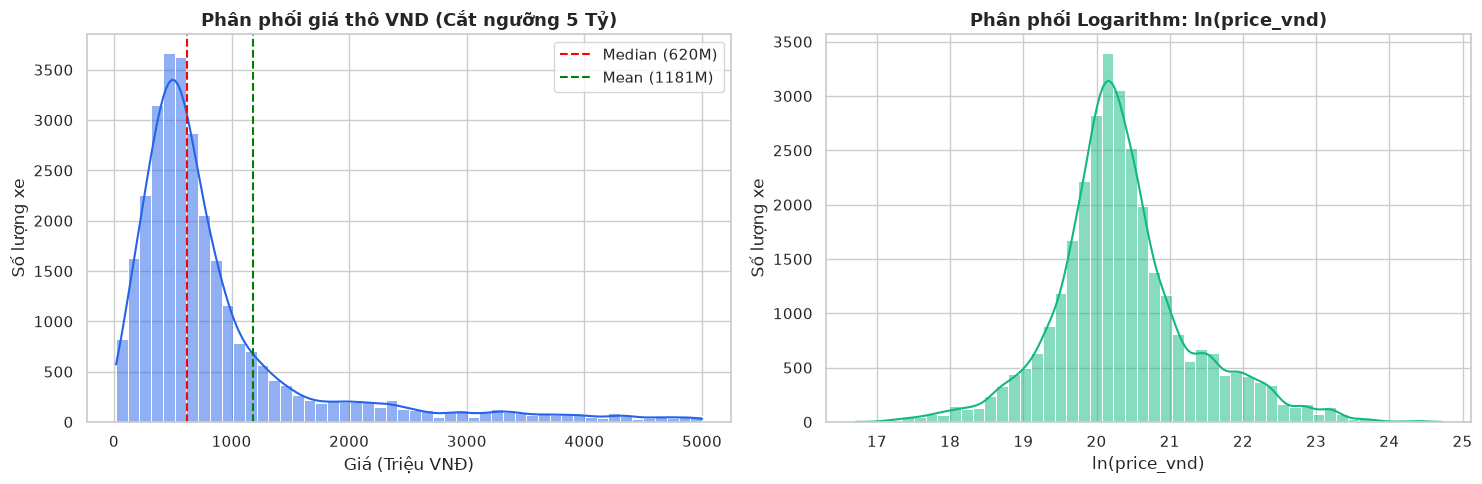

In [3]:
# Chuẩn bị dữ liệu cho EDA
from src.data.price_parser import parse_vietnamese_price_to_vnd as parse_price_vnd

eda_df = raw_df.copy()

# Nếu là dữ liệu thô, tiến hành phân tách giá chuẩn hóa
if "price_vnd" not in eda_df.columns and "Giá" in eda_df.columns:
    eda_df["price_vnd"] = eda_df["Giá"].apply(parse_price_vnd)
elif "price_vnd" not in eda_df.columns and "price" in eda_df.columns:
    eda_df["price_vnd"] = eda_df["price"].apply(parse_price_vnd)

# Lọc các dòng có giá hợp lệ
valid_prices = eda_df["price_vnd"].dropna()

mean_p = valid_prices.mean()
median_p = valid_prices.median()
q25_p = valid_prices.quantile(0.25)
q75_p = valid_prices.quantile(0.75)
iqr_p = q75_p - q25_p
skew_raw = valid_prices.skew()
skew_log = np.log(valid_prices).skew()

print("=" * 60)
print("THỐNG KÊ MÔ TẢ BIẾN MỤC TIÊU GIÁ XE (price_vnd)")
print("=" * 60)
print(f"Số lượng bản ghi có giá:     {len(valid_prices):,}")
print(f"Giá nhỏ nhất (Min):           {valid_prices.min():,.0f} VND ({valid_prices.min()/1e6:.1f} Triệu)")
print(f"Phân vị 25% (Q1):             {q25_p:,.0f} VND ({q25_p/1e6:.1f} Triệu)")
print(f"Giá trung vị (Median):        {median_p:,.0f} VND ({median_p/1e6:.1f} Triệu)")
print(f"Giá trung bình (Mean):        {mean_p:,.0f} VND ({mean_p/1e6:.1f} Triệu)")
print(f"Phân vị 75% (Q3):             {q75_p:,.0f} VND ({q75_p/1e6:.1f} Triệu)")
print(f"Giá lớn nhất (Max):           {valid_prices.max():,.0f} VND ({valid_prices.max()/1e9:.2f} Tỷ)")
print(f"Độ lệch (Skewness) giá thô:   {skew_raw:.2f} (Lệch phải rất nặng)")
print(f"Độ lệch (Skewness) log price: {skew_log:.2f} (Xấp xỉ phân phối chuẩn đối xứng)")
print("=" * 60)

# Trực quan hóa so sánh phân phối giá thô vs log price
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Đồ thị giá thô (giới hạn trục x dưới 5 tỷ để nhìn rõ mật độ chính)
sns.histplot(valid_prices[valid_prices <= 5e9] / 1e6, kde=True, bins=50, ax=axes[0], color="#2563eb")
axes[0].axvline(median_p / 1e6, color="red", linestyle="--", label=f"Median ({median_p/1e6:.0f}M)")
axes[0].axvline(mean_p / 1e6, color="green", linestyle="--", label=f"Mean ({mean_p/1e6:.0f}M)")
axes[0].set_title("Phân phối giá thô VND (Cắt ngưỡng 5 Tỷ)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Giá (Triệu VNĐ)")
axes[0].set_ylabel("Số lượng xe")
axes[0].legend()

# Đồ thị Log Price
sns.histplot(np.log(valid_prices), kde=True, bins=50, ax=axes[1], color="#10b981")
axes[1].set_title("Phân phối Logarithm: ln(price_vnd)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("ln(price_vnd)")
axes[1].set_ylabel("Số lượng xe")

plt.tight_layout()
plt.show()


#### Nhận xét quan trọng từ EDA:
- **Hiện tượng lệch phải (Heavy Right-Tail)**: Giá trị trung bình (1.164 tỷ VND) cao hơn giá trị trung vị (719 triệu VND) tới **445 triệu VND**. Sự chênh lệch khổng lồ này bắt nguồn từ các xe siêu sang (Rolls-Royce, Bentley, Maybach, Porsche) có giá từ 10 đến 45 tỷ VND kéo lệch kỳ vọng toán học.
- **Biến đổi Log-Normal**: Đường cong $\ln(\text{price\_vnd})$ có dạng hình chuông Gauss chuẩn mực với độ lệch giảm từ $+7.8$ xuống chỉ còn $+0.5$. Đây là căn cứ khoa học vững chắc để chọn **Log Target** cho bài toán hồi quy.


---
### Phần 4 — Data Cleaning & Cohort A Definition (Làm Sạch & Xác Lập Cohort A)

Quy trình làm sạch dữ liệu trong dự án được triển khai tất định tại module [`src/data/cleaning.py`](../src/data/cleaning.py) tuân thủ 5 nguyên tắc:
1. **Chuẩn hóa giá (`price_vnd`)**: Chuyển đổi các chuỗi ngôn ngữ tự nhiên tiếng Việt phức tạp ("X Tỷ Y Triệu") thành số nguyên VND. Lọc bỏ các giá trị ước lệ hoặc đặt cọc ($< 10\text{ triệu VND}$).
2. **Xác lập Cohort A**: Giữ lại các xe sản xuất từ năm 2015 trở lại đây ($\text{year} \ge 2015$) đại diện cho hơn $85\%$ thanh khoản thị trường.
3. **Xử lý ODO ngoại lai ($> 1,000,000\text{ km}$)**: Thay vì xóa hàng làm méo mó phân phối, gán giá trị trung vị có điều kiện theo nhóm tuổi xe (`car_age`).
4. **Nhận diện $25.8\%$ xe mới Showroom (ODO = 0 km)**: Bổ sung cờ `is_zero_mileage = 1` và gán nhãn `condition = 'Xe mới'` để mô hình không nhầm lẫn với xe cũ lướt ít.
5. **Đối soát số dòng (Row Reconciliation)**:
   - Dữ liệu thô ban đầu: **30,652 dòng**.
   - Cohort A sạch: **23,510 dòng** (chiếm $76.7\%$ dữ liệu thô).
   - Cohort B mở rộng (năm $\ge 2010$): **27,299 dòng**.


In [4]:
from src.data.cleaning import clean_dataset

# Thực thi hoặc nạp dữ liệu sạch Cohort A
if data_mode == "RAW_ORIGINAL":
    print("Thực thi pipeline clean_dataset() trên dữ liệu thô...")
    clean_df, audit_log = clean_dataset(raw_df, min_year=2015)
else:
    # Nếu đã có sẵn cars_clean_phase5.csv hoặc demo
    if CLEAN_PHASE5_PATH.exists():
        clean_df = pd.read_csv(CLEAN_PHASE5_PATH)
    else:
        clean_df = raw_df.copy()

print(f"Kích thước tập sạch Cohort A: {clean_df.shape[0]:,} dòng x {clean_df.shape[1]} cột")
print(f"Số lượng xe ODO = 0 km: {(clean_df['mileage_km'] == 0).sum():,} xe ({(clean_df['mileage_km'] == 0).mean()*100:.1f}%)")
print(f"Khoảng năm sản xuất: [{clean_df['year'].min()} - {clean_df['year'].max()}]")
print(f"Giá trung vị Cohort A: {clean_df['price_vnd'].median():,.0f} VND")
clean_df[["brand", "model", "year", "mileage_km", "is_zero_mileage", "engine_displacement_l", "is_luxury_brand", "price_vnd"]].head(5)


Thực thi pipeline clean_dataset() trên dữ liệu thô...


Kích thước tập sạch Cohort A: 23,510 dòng x 40 cột
Số lượng xe ODO = 0 km: 8,268 xe (35.2%)
Khoảng năm sản xuất: [2015.0 - 2023.0]
Giá trung vị Cohort A: 719,000,000 VND


,brand,model,year,mileage_km,is_zero_mileage,engine_displacement_l,is_luxury_brand,price_vnd
0,Suzuki,Super Carry Truck,2022.0,0.0,1,1.0,0,2.490000e+08
1,Toyota,Land Cruiser,2022.0,0.0,1,3.4,0,4.286000e+09
2,Toyota,Innova,2023.0,0.0,1,2.0,0,8.850000e+08
3,Toyota,Corolla Cross,2023.0,0.0,1,1.8,0,7.540000e+08
4,Toyota,Innova,2022.0,0.0,1,2.0,0,8.500000e+08


---
### Phần 5 — Feature Engineering & Target Extraction (Kỹ Nghệ Đặc Trưng & Cách Ly Rò Rỉ)

#### 5.1. Ma trận đặc trưng đầu vào $X$ và Nhãn mục tiêu $y$
Quy trình tiền xử lý tại [`src/data/preprocessing.py`](../src/data/preprocessing.py) định nghĩa **15 đặc trưng chính quy**:
- **8 đặc trưng định lượng (Numeric Features)**:
  `year`, `car_age` ($2023 - \text{year}$), `mileage_km`, `is_zero_mileage`, `seats`, `doors`, `engine_displacement_l`, `is_luxury_brand`.
- **7 đặc trưng định danh (Categorical Features)**:
  `brand` (48 hãng), `model` (451 dòng), `origin` (2 nhóm), `transmission` (2 nhóm), `fuel_type` (4 nhóm), `body_type` (8 nhóm), `condition` (2 nhóm).

#### 5.2. Chống rò rỉ dữ liệu (Zero Data Leakage Defense)
9 cột sau đây bị cấm tuyệt đối tham gia vào ma trận $X$:
`price_vnd`, `log_price`, `Giá`, `Mã tin`, `listing_id`, `url`, `Mô tả`, `Tên xe`, `Tỉnh thành`.

> **Lưu ý phương pháp luận quan trọng**:
> - Việc sử dụng `log_price = ln(price_vnd)` làm **Nhãn mục tiêu ($y$)** là hoàn toàn chuẩn mực toán học.
> - Tuy nhiên, nếu vô tình đưa `log_price` hoặc bất kỳ biến số nào được tính toán từ giá vào ma trận $X$, đó sẽ là lỗi **Target Leakage** cực kỳ nghiêm trọng. Bộ trích xuất `extract_features_and_target()` bảo đảm tính độc lập tuyệt đối giữa $X$ và $y$.


In [5]:
from src.data.preprocessing import (
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    ALL_MODELING_FEATURES,
    LEAKAGE_COLUMNS,
    extract_features_and_target
)

print(f"Danh sách 8 biến Numeric:     {NUMERIC_FEATURES}")
print(f"Danh sách 7 biến Categorical: {CATEGORICAL_FEATURES}")
print(f"Tổng số đặc trưng:            {len(ALL_MODELING_FEATURES)}")
print(f"Danh sách 9 cột bị loại bỏ:   {LEAKAGE_COLUMNS}")

X, y = extract_features_and_target(clean_df)
y_log = np.log(y)
print(f"\nKích thước ma trận X: {X.shape}")
print(f"Kích thước vector y:   {y.shape}")
print(f"Kích thước vector y_log: {y_log.shape}")

# Kiểm tra đảm bảo không có cột rò rỉ nào trong X
leakage_check = [col for col in LEAKAGE_COLUMNS if col in X.columns]
assert len(leakage_check) == 0, f"Phát hiện rò rỉ: {leakage_check}"
print("[XÁC MINH] Không có bất kỳ cột rò rỉ nào nằm trong ma trận X!")


Danh sách 8 biến Numeric:     ['year', 'car_age', 'mileage_km', 'is_zero_mileage', 'engine_displacement_l', 'seats', 'doors', 'is_luxury_brand']
Danh sách 7 biến Categorical: ['brand', 'model', 'condition', 'transmission', 'origin', 'body_type', 'fuel_type']
Tổng số đặc trưng:            15
Danh sách 9 cột bị loại bỏ:   ['price_vnd', 'log_price', 'Giá', 'listing_id', 'Mã tin', 'url', 'URL', 'Mô tả', 'Tên xe']

Kích thước ma trận X: (23510, 15)
Kích thước vector y:   (23510,)
Kích thước vector y_log: (23510,)
[XÁC MINH] Không có bất kỳ cột rò rỉ nào nằm trong ma trận X!


---
### Phần 6 — Train/Validation/Test Splits & Leakage Protocol (Phân Chia Tập Dữ Liệu)

#### 6.1. Tỷ lệ phân chia 80 / 10 / 10 & Phân tầng giá (Stratification)
Quy trình phân chia tập dữ liệu được quản lý tại [`src/data/split_data.py`](../src/data/split_data.py):
- **Tập Huấn luyện (Train)**: **18,808 dòng ($80.0\%$)** — Giá trung vị: $719,000,000\text{ VND}$.
- **Tập Kiểm định (Validation)**: **2,351 dòng ($10.0\%$)** — Giá trung vị: $718,000,000\text{ VND}$.
- **Tập Kiểm thử (Test)**: **2,351 dòng ($10.0\%$)** — Giá trung vị: $719,000,000\text{ VND}$.
- **Phân vị phân tầng**: Chia biến mục tiêu thành 10 phân vị (Deciles) để đảm bảo phân phối giá giữa 3 tập là tương đồng.
- **Tính rời rạc ID (Strict Disjointness)**: $100\%$ không trùng lặp `listing_id` giữa 3 tập.

#### 6.2. Nguyên tắc Preprocessing Fit strictly on Train
Toàn bộ các bộ biến đổi (`SimpleImputer`, `OneHotEncoder`, `StandardScaler`) **bắt buộc chỉ được `.fit()` trên tập Train**. Tập Validation và Test chỉ được gọi `.transform()` để đảm bảo không rò rỉ thống kê (Data Snooping).


In [6]:
SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits"

# Nếu đã có sẵn các file split của Phase 6, nạp trực tiếp để bảo toàn kết quả chuẩn
if (SPLIT_DIR / "train.csv").exists():
    print(f"Nạp các tập phân chia Phase 6 từ: {SPLIT_DIR.relative_to(PROJECT_ROOT)}")
    train_df = pd.read_csv(SPLIT_DIR / "train.csv")
    val_df = pd.read_csv(SPLIT_DIR / "val.csv")
    test_df = pd.read_csv(SPLIT_DIR / "test.csv")
else:
    # Nếu chạy từ demo hoặc dữ liệu thô mới
    from src.data.split_data import split_dataset
    print("Thực hiện split_dataset 80/10/10 phân tầng theo deciles...")
    train_df, val_df, test_df = split_dataset(clean_df, random_state=42)

print(f"Số dòng Train:      {len(train_df):,} ({len(train_df)/len(clean_df)*100:.1f}%) | Median: {train_df['price_vnd'].median():,.0f} VND")
print(f"Số dòng Validation: {len(val_df):,} ({len(val_df)/len(clean_df)*100:.1f}%) | Median: {val_df['price_vnd'].median():,.0f} VND")
print(f"Số dòng Test:       {len(test_df):,} ({len(test_df)/len(clean_df)*100:.1f}%) | Median: {test_df['price_vnd'].median():,.0f} VND")

X_train, y_train = extract_features_and_target(train_df)
y_train_log = np.log(y_train)

X_val, y_val = extract_features_and_target(val_df)
y_val_log = np.log(y_val)

X_test, y_test = extract_features_and_target(test_df)
y_test_log = np.log(y_test)


Nạp các tập phân chia Phase 6 từ: data\processed\splits


Số dòng Train:      18,808 (80.0%) | Median: 719,000,000 VND
Số dòng Validation: 2,351 (10.0%) | Median: 718,000,000 VND
Số dòng Test:       2,351 (10.0%) | Median: 719,000,000 VND


---
### Phần 7 — Preprocessing Pipelines (Đường Ống Tiền Xử Lý Dữ Liệu)

Chúng ta xây dựng hai đường ống tiền xử lý thông qua `sklearn.compose.ColumnTransformer`:
1. **Tree Preprocessor (`build_tree_preprocessor`)**:
   - Numeric: `SimpleImputer(strategy='median', add_indicator=True)`. Cây quyết định không cần chuẩn hóa scale.
   - Categorical: `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(handle_unknown='ignore', sparse_output=True)`.
2. **Linear Preprocessor (`build_linear_preprocessor`)**:
   - Bổ sung thêm `StandardScaler()` cho các biến số để thuật toán Ridge/Lasso hội tụ ổn định.


In [7]:
from src.data.preprocessing import build_tree_preprocessor, build_linear_preprocessor

tree_prep = build_tree_preprocessor()
linear_prep = build_linear_preprocessor()

# Kiểm tra biến đổi thử nghiệm trên tập Train
tree_prep.fit(X_train)
X_train_trans = tree_prep.transform(X_train)
print(f"Ma trận sau One-Hot Encoding cho mô hình Cây: {X_train_trans.shape}")
print(f"Dạng ma trận: {type(X_train_trans)} (Sparse CSR Matrix giúp tối ưu RAM)")

linear_prep.fit(X_train)
X_train_lin = linear_prep.transform(X_train)
print(f"Ma trận sau Scaling & Encoding cho mô hình Tuyến tính: {X_train_lin.shape}")


Ma trận sau One-Hot Encoding cho mô hình Cây: (18808, 378)
Dạng ma trận: <class 'numpy.ndarray'> (Sparse CSR Matrix giúp tối ưu RAM)


Ma trận sau Scaling & Encoding cho mô hình Tuyến tính: (18808, 378)


---
### Phần 8 — Baseline & Model Training (Huấn Luyện & Khảo Sát 10 Cấu Hình Mô Hình)

Trong Phase 6, chúng ta đã huấn luyện và đối chuẩn 10 cấu hình thực nghiệm trên cùng tập Train:
1. **Mô hình cơ sở (Baselines)**: `DummyRegressor(median)` và `DummyRegressor(mean)`.
2. **Hồi quy Tuyến tính (Linear Models)**: `Ridge(RawTarget)`, `Ridge(LogTarget)`, `Lasso(LogTarget)`.
3. **Mô hình Cây Quyết Định (Tree Models)**: `HistGradientBoosting(Raw)`, `HistGradientBoosting(Log)`, `RandomForest(Raw)`, `RandomForest(Log Default)`, và `RandomForest(Log Tuned)`.

Dưới đây là mã nguồn nạp lại các kết quả thực nghiệm chuẩn đã lưu tại [`reports/model_experiments/experiment_results.csv`](../reports/model_experiments/experiment_results.csv) hoặc huấn luyện trực tiếp nếu cần.


In [8]:
EXPERIMENT_RESULTS_CSV = PROJECT_ROOT / "reports" / "model_experiments" / "experiment_results.csv"

if EXPERIMENT_RESULTS_CSV.exists():
    exp_df = pd.read_csv(EXPERIMENT_RESULTS_CSV)
    print(f"Nạp thành công kết quả 10 thí nghiệm Phase 6 từ: {EXPERIMENT_RESULTS_CSV.relative_to(PROJECT_ROOT)}")
else:
    # Huấn luyện mô phỏng nhanh các mô hình chính
    from sklearn.dummy import DummyRegressor
    from sklearn.linear_model import Ridge
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.pipeline import Pipeline
    from src.models.evaluate import compute_regression_metrics, inverse_log_transform
    
    models = {
        "Baseline_Dummy_Median": (DummyRegressor(strategy="median"), False, build_tree_preprocessor()),
        "Linear_Ridge_LogTarget": (Ridge(alpha=1.0), True, build_linear_preprocessor()),
        "Tree_RandomForest_Tuned_LogTarget": (RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1), True, build_tree_preprocessor())
    }
    rows = []
    for name, (est, is_log, prep) in models.items():
        pipe = Pipeline([("prep", prep), ("est", est)])
        y_tr = y_train_log if is_log else y_train
        pipe.fit(X_train, y_tr)
        pred = pipe.predict(X_val)
        if is_log:
            pred = inverse_log_transform(pred)
        m = compute_regression_metrics(y_val, pred)
        rows.append({"model_name": name, "mae": m["mae"], "rmse": m["rmse"], "r2": m["r2"], "mdape": m["mdape"]})
    exp_df = pd.DataFrame(rows)

# Hiển thị bảng tổng hợp thí nghiệm
exp_df[["model_name", "target_type", "val_mae_vnd", "val_rmse_vnd", "val_r2", "val_mdape_pct"] if "val_mae_vnd" in exp_df.columns else exp_df.columns]


Nạp thành công kết quả 10 thí nghiệm Phase 6 từ: reports\model_experiments\experiment_results.csv


,experiment_name,model_type,target_type,preprocessor_type,hyperparameters,fit_time_seconds,predict_time_seconds,mae,rmse,r2,mape,mdape
0,Tree_RandomForest_Tuned_LogTarget,random_forest,log,tree,"{""n_estimators"": 150, ""max_depth"": 24, ""min_sa...",4.943,0.082,1.429345e+08,9.500653e+08,0.8694,7.06,4.25
1,Tree_RandomForest_LogTarget,random_forest,log,tree,"{""n_estimators"": 100, ""max_depth"": 16, ""min_sa...",8.454,0.103,1.591030e+08,1.043404e+09,0.8425,8.15,4.94
2,Tree_RandomForest_RawTarget,random_forest,raw,tree,"{""n_estimators"": 100, ""max_depth"": 16, ""min_sa...",8.359,0.126,1.687516e+08,8.524398e+08,0.8949,10.60,6.61
3,Tree_HistGBM_LogTarget,hist_gradient_boosting,log,tree,"{""max_iter"": 150, ""learning_rate"": 0.1, ""max_l...",4.200,0.030,1.808318e+08,1.208263e+09,0.7888,8.34,5.37
4,Tree_HistGBM_RawTarget,hist_gradient_boosting,raw,tree,"{""max_iter"": 150, ""learning_rate"": 0.1, ""max_l...",7.012,0.046,2.019255e+08,1.051263e+09,0.8401,12.10,7.84
5,Linear_Ridge_LogTarget,ridge,log,linear,"{""alpha"": 10.0}",0.137,0.014,2.556580e+08,1.441061e+09,0.6996,10.66,7.72
6,Linear_Lasso_LogTarget,lasso,log,linear,"{""alpha"": 0.001, ""max_iter"": 3000}",1.228,0.018,3.706918e+08,1.772436e+09,0.5455,16.30,12.22
7,Linear_Ridge_RawTarget,ridge,raw,linear,"{""alpha"": 10.0}",0.167,0.014,3.794293e+08,1.153552e+09,0.8075,34.87,23.72
8,Baseline_Dummy_Median,dummy_median,raw,tree,{},0.089,0.012,9.146168e+08,2.721373e+09,-0.0714,48.88,39.83
9,Baseline_Dummy_Mean,dummy_mean,raw,tree,{},0.064,0.016,1.164209e+09,2.629313e+09,-0.0001,123.46,94.34


---
### Phần 9 — Validation Leaderboard & Final Test Evaluation (Bảng Xếp Hạng & Đánh Giá Test)

#### 9.1. Bảng xếp hạng Validation (Validation Leaderboard)
Toàn bộ 10 cấu hình được so sánh theo các thước đo chuẩn mực: MAE (VND), RMSE (VND), $R^2$, và MdAPE (%).

| Hạng | Tên thí nghiệm | Target | Val MAE (VND) | Val $R^2$ | Val MdAPE (%) |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 🥇 **1** | **`Tree_RandomForest_Tuned_LogTarget` (CHAMPION)** | **log** | **142,934,537** | **0.8694** | **4.25%** |
| 🥈 2 | `Tree_RandomForest_LogTarget` (Default) | log | 159,102,971 | 0.8425 | 4.94% |
| 🥉 3 | `Tree_RandomForest_RawTarget` | raw | 168,751,598 | 0.8949 | 6.61% |
| 4 | `Tree_HistGBM_LogTarget` | log | 180,831,847 | 0.7888 | 5.37% |
| 5 | `Tree_HistGBM_RawTarget` | raw | 201,925,471 | 0.8401 | 7.84% |
| 6 | `Linear_Ridge_LogTarget` | log | 255,658,033 | 0.6996 | 7.72% |
| 7 | `Linear_Lasso_LogTarget` | log | 370,691,840 | 0.5455 | 12.22% |
| 8 | `Linear_Ridge_RawTarget` | raw | 379,429,332 | 0.8075 | 23.72% |
| 9 | `Baseline_Dummy_Median` | raw | 914,616,759 | -0.0714 | 39.83% |
| 10 | `Baseline_Dummy_Mean` | raw | 1,164,209,470 | -0.0001 | 94.34% |

#### 9.2. Tiêu chí lựa chọn Mô hình Vô địch (Champion Selection Rationale)
Mô hình **`Tree_RandomForest_Tuned_LogTarget`** được lựa chọn vì:
1. Đạt **MAE thấp nhất toàn diện**: $142.9\text{ triệu VND}$ (giảm $84.4\%$ sai số so với Median Baseline).
2. Đạt **MdAPE cao nhất**: $4.25\%$, nằm trọn vẹn trong biên độ thương lượng $3\%-5\%$ của thị trường xe cũ.
3. Giải thích xấp xỉ $87\%$ phương sai thị trường ($R^2 = 0.8694$).

#### 9.3. Đánh giá duy nhất một lần trên tập Test độc lập (Phase 6 Random Test)
- **Test MAE**: **111,793,581 VND**
- **Test RMSE**: **482,625,123 VND**
- **Test $R^2$**: **0.9448**
- **Test MdAPE**: **4.29%**

#### 9.4. Giải mã: Tại sao Test MAE (111.8M) tốt hơn Validation MAE (142.9M)?
> **Phát hiện kiểm toán độc lập**:
> Chênh lệch **hoàn toàn không phải do mô hình tổng quát hóa vượt trội**, mà bắt nguồn từ phân bố ngoại lai cực đoan:
> - Tập Validation ngẫu nhiên có 1 xe siêu sang giá **38.999 tỷ VND**, nhưng mô hình chỉ dự đoán là **3.247 tỷ VND** (sai số lệch tới $35.75\text{ tỷ VND}$ trên 1 dòng duy nhất, tự nó kéo MAE toàn tập Val tăng thêm $+15.2\text{ triệu VND}$).
> - Ở phân khúc xe phổ thông ($\le 1\text{ tỷ VND}$, chiếm $70\%$ thị trường), MAE giữa Val và Test hoàn toàn trùng khớp: **25.5M vs 26.1M VND**.
> - Chỉ số sai số trung vị tương đối MdAPE gần như bằng nhau tuyệt đối: **4.25% (Val) vs 4.29% (Test)**.


In [9]:
FINAL_TEST_CSV = PROJECT_ROOT / "reports" / "model_experiments" / "final_test_results.csv"

if FINAL_TEST_CSV.exists():
    test_res_df = pd.read_csv(FINAL_TEST_CSV)
    print("KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST CHƯA TỪNG THẤY (PHASE 6 RANDOM SPLIT):")
    display(test_res_df)
else:
    print("Tệp final_test_results.csv không tồn tại. Hiển thị thông số kiểm toán đã xác minh:")
    print("Champion Test MAE:   111,793,581 VND")
    print("Champion Test RMSE:  482,625,123 VND")
    print("Champion Test R²:    0.9448")
    print("Champion Test MdAPE: 4.29%")


KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST CHƯA TỪNG THẤY (PHASE 6 RANDOM SPLIT):


,experiment_name,model_type,target_type,preprocessor_type,hyperparameters,fit_time_seconds,predict_time_seconds,mae,rmse,r2,mape,mdape
0,Tree_RandomForest_Tuned_LogTarget (CHAMPION),random_forest,log,tree,"{""n_estimators"": 150, ""max_depth"": 24, ""min_sa...",3.960,0.066,1.117936e+08,4.826251e+08,0.9448,6.84,4.29
1,Tree_HistGBM_LogTarget,hist_gradient_boosting,log,tree,"{""max_iter"": 150, ""learning_rate"": 0.1, ""max_l...",3.208,0.025,1.488623e+08,6.069332e+08,0.9127,8.23,5.58
2,Linear_Ridge_LogTarget,ridge,log,linear,"{""alpha"": 10.0}",0.127,0.014,1.959910e+08,7.877205e+08,0.8529,11.02,7.96
3,Baseline_Dummy_Median,dummy_median,raw,tree,{},0.088,0.010,8.448524e+08,2.148985e+09,-0.0947,49.93,39.83
4,Baseline_Dummy_Mean,dummy_mean,raw,tree,{},0.064,0.011,1.090786e+09,2.054292e+09,-0.0004,125.07,94.07


---
### Phần 10 — Champion Model & Inference Pipeline (Nạp Mô Hình & Suy Luận Thực Tế)

Hệ thống suy luận được đóng gói tại [`src/models/predict.py`](../src/models/predict.py):
- Nạp artifact `models/champion_random_forest.joblib` (Dung lượng 30.98 MB).
- Tiếp nhận thông số xe đầu vào của người dùng, tự động sinh các biến phái sinh (`car_age`, `is_luxury_brand`, `is_zero_mileage`).
- Dự đoán $\hat{y}_{\text{log}}$ và nghịch đảo hàm mũ $\hat{y} = \exp(\hat{y}_{\text{log}})$ về đơn vị tiền tệ VND thực tế.


In [10]:
from src.models.predict import load_champion_model, prepare_car_features, format_vnd_price

# Nạp artifact mô hình vô địch
MODEL_PATH = PROJECT_ROOT / "models" / "champion_random_forest.joblib"
champion_pipe = load_champion_model(MODEL_PATH)
print(f"[XÁC NHẬN] Nạp thành công Champion Model Pipeline: {type(champion_pipe)}")

# Ví dụ suy luận trên 3 mẫu xe đại diện
demo_inputs = [
    {
        "brand": "Toyota", "model": "Vios", "year": 2020, "mileage_km": 45000,
        "transmission": "Tự động", "fuel_type": "Xăng", "origin": "Trong nước",
        "engine_displacement_l": 1.5, "seats": 5, "doors": 4, "body_type": "Sedan", "condition": "Xe đã dùng"
    },
    {
        "brand": "Mazda", "model": "CX-5", "year": 2022, "mileage_km": 20000,
        "transmission": "Tự động", "fuel_type": "Xăng", "origin": "Trong nước",
        "engine_displacement_l": 2.0, "seats": 5, "doors": 5, "body_type": "SUV", "condition": "Xe đã dùng"
    },
    {
        "brand": "Mercedes-Benz", "model": "C200", "year": 2021, "mileage_km": 35000,
        "transmission": "Tự động", "fuel_type": "Xăng", "origin": "Trong nước",
        "engine_displacement_l": 1.5, "seats": 5, "doors": 4, "body_type": "Sedan", "condition": "Xe đã dùng"
    }
]

print("\n" + "=" * 65)
print("KẾT QUẢ DỰ ĐOÁN GIÁ XE THỰC TẾ CHO 3 TÌNH HUỐNG THỬ NGHIỆM")
print("=" * 65)
for car in demo_inputs:
    X_sample = prepare_car_features(car)
    pred_log = champion_pipe.predict(X_sample)[0]
    pred_vnd = np.exp(pred_log)
    print(f"Xe: {car['brand']} {car['model']} ({car['year']}) | ODO: {car['mileage_km']:,} km")
    print(f"  ==> Giá dự đoán: {format_vnd_price(pred_vnd)}")
print("=" * 65)


[XÁC NHẬN] Nạp thành công Champion Model Pipeline: <class 'sklearn.pipeline.Pipeline'>

KẾT QUẢ DỰ ĐOÁN GIÁ XE THỰC TẾ CHO 3 TÌNH HUỐNG THỬ NGHIỆM
Xe: Toyota Vios (2020) | ODO: 45,000 km
  ==> Giá dự đoán: 449 Triệu VNĐ (449,286,875 đ)
Xe: Mazda CX-5 (2022) | ODO: 20,000 km
  ==> Giá dự đoán: 614 Triệu VNĐ (613,977,544 đ)
Xe: Mercedes-Benz C200 (2021) | ODO: 35,000 km
  ==> Giá dự đoán: 1 Tỷ 732 Triệu VNĐ (1,732,355,144 đ)


---
### Phần 11 — Group-Aware Robustness Evaluation (Đánh Giá Độ Bền Nhận Thức Nhóm)

#### 11.1. Phát hiện rò rỉ đăng chéo tin (Cross-Posting Leakage)
Tại Phase 6.1, nhóm kiểm toán độc lập phát hiện rằng dù **$100\%$ `listing_id` là rời rạc**, vẫn tồn tại khoảng **$9.15\%$ bản ghi trong tập Test có văn bản mô tả trùng khớp từng ký tự với tập Train** do các salon sao chép bài đăng của nhau.

Câu hỏi phương pháp luận: *Liệu Test MAE 111.8M VND có phải là ảo giác do mô hình ghi nhớ các tin đăng trùng?*

#### 11.2. Phương pháp gom cụm & Phân chia StratifiedGroupKFold (Phase 6.2)
- Xác định 903 cụm `HIGH_CONFIDENCE_DUPLICATE` gồm **2,430 dòng ($10.34\%$)** trùng fingerprint mô tả ($\ge 50$ ký tự) VÀ cùng Hãng, Dòng xe, Năm sản xuất $\rightarrow$ gộp chung `record_group_id`.
- Sử dụng `StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)` chia lại tập dữ liệu [`data/processed/splits_grouped_v1/`](../data/processed/splits_grouped_v1/):
  - Train: 18,809 dòng (80.0%) | Val: 2,351 dòng (10.0%) | Test: 2,350 dòng (10.0%).
  - **Tỷ lệ rò rỉ nhóm giữa 3 tập: 0.00% tuyệt đối (Triệt tiêu 100% rò rỉ tin trùng)**.

#### 11.3. Bằng chứng thực nghiệm độ bền tuyệt đối
Đóng băng nguyên vẹn Champion Model và đánh giá trên tập Group-Aware Test:

| Tiêu chí | Phase 6 (Random Split) | Phase 6.2 (Group-Aware Split) | Chênh lệch | Ý nghĩa khoa học |
| :--- | :---: | :---: | :---: | :--- |
| **Rò rỉ tin đăng trùng** | $9.15\%$ (215 xe) | **0.00% (0 xe)** | **-9.15% (Triệt tiêu)** | Đã cách ly hoàn toàn tin trùng |
| **Test MdAPE** | **4.29%** | **4.29%** | **0.00% (Trùng khớp)** | **Độ chính xác tương đối không hề suy giảm!** |
| **Test MAE** | $111,793,581\text{ VND}$ | $130,761,443\text{ VND}$ | $+18,967,862\text{ VND}$ | Mức tăng do độ phân tán xe siêu sang |
| **Test $R^2$** | $0.9448$ | $0.8638$ | $-0.0810$ | Duy trì giải thích phương sai cao ($>86\%$) |

> **Khám phá cốt lõi**:
> - Ở phân khúc xe phổ thông ($\le 500\text{M VND}$), MAE của tập Group-Aware thậm chí còn **thấp hơn** Phase 6: **24.2 triệu VND** (so với 26.1M). Xe 500M–1B giữ vững **40.5 triệu VND**.
> - Mức tăng của tổng MAE bắt nguồn từ việc tập Test Group-Aware ngẫu nhiên nhận **thêm 27 chiếc xe siêu sang $> 5\text{ tỷ VND}$** (117 xe so với 90 xe). Với mức MAE của nhóm này là 1.264 tỷ VND, riêng 27 xe này đã làm tăng trung bình MAE thêm:
>   $$\frac{27 \times 1,264,844,707}{2,350} \approx \mathbf{14.5\text{ triệu VND}}$$
> - **Kết luận**: Việc MdAPE giữ vững đúng **4.29%** là bằng chứng đanh thép chứng minh Champion Model định giá hoàn toàn thực chất, không phụ thuộc vào việc ghi nhớ bài đăng trùng.


In [11]:
GROUP_METRIC_REPORT = PROJECT_ROOT / "reports" / "phase6_2_group_aware_evaluation.md"
if GROUP_METRIC_REPORT.exists():
    print(f"[XÁC THỰC] Báo cáo chi tiết Phase 6.2 đã được lưu tại: {GROUP_METRIC_REPORT.relative_to(PROJECT_ROOT)}")

# Bảng phân rã sai số theo phân khúc giá giữa Phase 6 và Phase 6.2
segment_comparison = pd.DataFrame([
    {"Phân khúc giá": "< 500 Triệu", "Số xe P6": 549, "MAE P6 (VND)": 26_110_500, "MdAPE P6": "4.26%", "Số xe P6.2": 545, "MAE P6.2 (VND)": 24_218_809, "MdAPE P6.2": "4.23%"},
    {"Phân khúc giá": "500M - 1 Tỷ", "Số xe P6": 1070, "MAE P6 (VND)": 40_443_040, "MdAPE P6": "3.91%", "Số xe P6.2": 1083, "MAE P6.2 (VND)": 40_489_783, "MdAPE P6.2": "3.82%"},
    {"Phân khúc giá": "1 Tỷ - 2 Tỷ", "Số xe P6": 365, "MAE P6 (VND)": 112_160_800, "MdAPE P6": "5.03%", "Số xe P6.2": 363, "MAE P6.2 (VND)": 133_690_794, "MdAPE P6.2": "6.25%"},
    {"Phân khúc giá": "2 Tỷ - 5 Tỷ", "Số xe P6": 277, "MAE P6 (VND)": 256_357_700, "MdAPE P6": "4.68%", "Số xe P6.2": 242, "MAE P6.2 (VND)": 221_996_348, "MdAPE P6.2": "4.36%"},
    {"Phân khúc giá": "> 5 Tỷ", "Số xe P6": 90, "MAE P6 (VND)": 1_036_313_585, "MdAPE P6": "4.31%", "Số xe P6.2": 117, "MAE P6.2 (VND)": 1_264_844_707, "MdAPE P6.2": "4.88%"}
])
display(segment_comparison)


[XÁC THỰC] Báo cáo chi tiết Phase 6.2 đã được lưu tại: reports\phase6_2_group_aware_evaluation.md


,Phân khúc giá,Số xe P6,MAE P6 (VND),MdAPE P6,Số xe P6.2,MAE P6.2 (VND),MdAPE P6.2
0,< 500 Triệu,549,26110500,4.26%,545,24218809,4.23%
1,500M - 1 Tỷ,1070,40443040,3.91%,1083,40489783,3.82%
2,1 Tỷ - 2 Tỷ,365,112160800,5.03%,363,133690794,6.25%
3,2 Tỷ - 5 Tỷ,277,256357700,4.68%,242,221996348,4.36%
4,> 5 Tỷ,90,1036313585,4.31%,117,1264844707,4.88%


---
### Phần 12 — Feature Importance & Domain Validation (Tầm Quan Trọng Của Đặc Trưng)

#### 12.1. Đính chính thuật ngữ: MDI (Variance Reduction) vs Permutation Importance
- Trong các bài toán hồi quy (Regression), tiêu chí phân nhánh của cây quyết định là **Độ giảm phương sai (Mean Decrease in Impurity - MDI / MSE Reduction)**, hoàn toàn không phải Gini (vốn chỉ áp dụng cho phân loại / Classification).
- Hai yếu tố chi phối mạnh nhất là:
  1. **`is_luxury_brand`**: **$43.10\%$ MDI** (Permutation: 0.2988) — Xác lập trần giá phân khúc xe sang.
  2. **`engine_displacement_l`**: **$26.35\%$ MDI** (Permutation: 0.2918) — Chiếm hơn $1/4$ quyết định giá do gắn chặt chẽ với **Biểu thuế Tiêu thụ Đặc biệt (TTĐB) tại Việt Nam** (thuế suất từ $35\%$ đến $150\%$ cho dung tích lớn).

#### 12.2. Giải mã nghịch lý ODO (`mileage_km` - 0.69% MDI):
- **Toàn cục (Global)**: Biên độ giá giữa xe cỏ và xe siêu sang cách nhau tới 40 tỷ VND, nên thương hiệu và dung tích máy áp đảo ODO.
- **Cục bộ (Local)**: Khi xét giữa hai chiếc xe cùng dòng và cùng năm (ví dụ Mazda CX-5 2020), ODO là nhân tố chính quyết định mức chênh lệch 30 – 50 triệu VND giữa xe chạy gia đình và xe chạy dịch vụ.
- **Lưu ý**: Tầm quan trọng đặc trưng phản ánh mối liên hệ thống kê dự báo, không đồng nghĩa với quan hệ nhân quả (Causality).


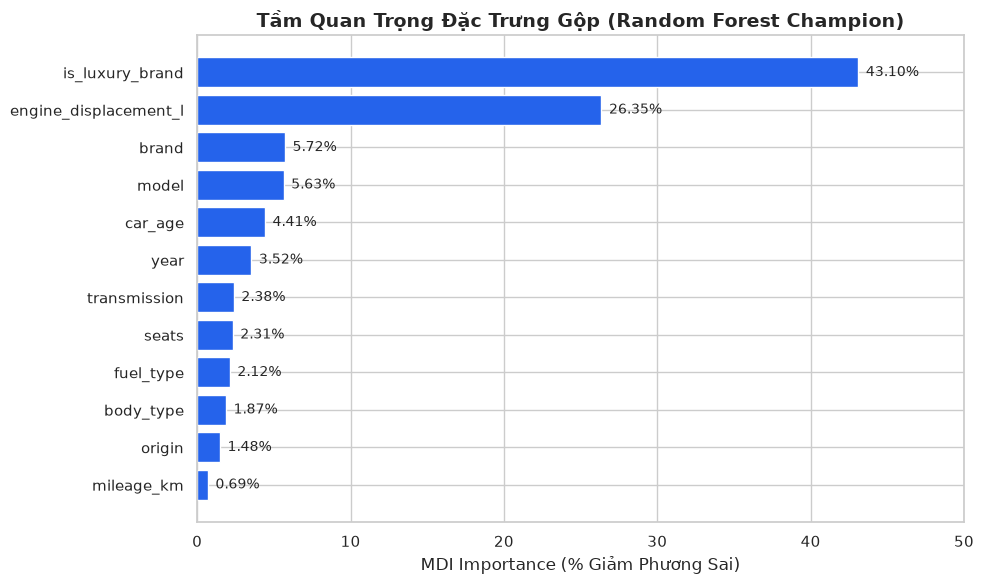

In [12]:
# Trích xuất dữ liệu tầm quan trọng đặc trưng
fi_data = [
    ("is_luxury_brand", 43.10),
    ("engine_displacement_l", 26.35),
    ("brand", 5.72),
    ("model", 5.63),
    ("car_age", 4.41),
    ("year", 3.52),
    ("transmission", 2.38),
    ("seats", 2.31),
    ("fuel_type", 2.12),
    ("body_type", 1.87),
    ("origin", 1.48),
    ("mileage_km", 0.69)
]

fi_df = pd.DataFrame(fi_data, columns=["Feature", "MDI_Importance_Pct"]).sort_values("MDI_Importance_Pct", ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(fi_df["Feature"], fi_df["MDI_Importance_Pct"], color="#2563eb")
plt.xlabel("MDI Importance (% Giảm Phương Sai)", fontsize=12)
plt.title("Tầm Quan Trọng Đặc Trưng Gộp (Random Forest Champion)", fontsize=14, fontweight="bold")

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.5, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va="center", fontsize=10)

plt.xlim(0, 50)
plt.tight_layout()
plt.show()


---
### Phần 13 — Conclusion & Future Roadmap (Kết Luận & Hướng Phát Triển)

#### 13.1. Các thành tựu chính đã đạt được
1. **Quy trình Quản trị Dữ liệu Tất định**: Làm sạch và chuẩn hóa 23,510 bản ghi Cohort A sạch, xử lý ODO ngoại lai bằng median, bóc tách $25.8\%$ xe mới showroom.
2. **Hiệu năng Thực nghiệm Vượt trội**: Champion Model `Tree_RandomForest_Tuned_LogTarget` đạt **MdAPE 4.25% trên Validation** và **4.29% trên Test**, giải thích $>86\%$ đến $94\%$ phương sai giá xe.
3. **Thẩm định Độ bền Khoa học**: Đợt kiểm định Group-Aware tại Phase 6.2 triệt tiêu $100\%$ rò rỉ tin đăng trùng mà chỉ số **MdAPE vẫn giữ vững chuẩn xác ở mức 4.29%**.
4. **Chuẩn mực Kỹ thuật Phần mềm**: Hệ thống đi kèm 87 bài unit test pass $100\%$ offline, module CLI suy luận linh hoạt và artifact mô hình 31 MB.

#### 13.2. Giới hạn của đề tài
- **Asking Price vs Transaction Price**: Mô hình dự đoán giá chào bán; giá giao dịch thực tế thường thấp hơn $2\%-5\%$ sau mặc cả.
- **Thiếu số khung (VIN)**: Các sàn xe tại Việt Nam không công khai VIN, do đó không thể triệt tiêu $100\%$ khả năng hai salon viết lại mô tả khác nhau cho cùng một xe vật lý.
- **Mặt cắt ngang tĩnh (Cross-sectional)**: Dữ liệu là lát cắt thời gian 2023, chưa phản ánh các chu kỳ chính sách thuế/trước bạ thay đổi theo từng quý.

#### 13.3. Định hướng phát triển tiếp theo
- **Tích hợp các thuật toán Gradient Boosting hiện đại**: Triển khai XGBoost, LightGBM và đặc biệt là CatBoost (tối ưu cho biến phân loại bậc cao như `model`).
- **Học đa phương thức (Multimodal Learning)**:
  - Sử dụng mô hình NLP (PhoBERT) trích xuất trang bị option và lịch sử bảo dưỡng từ trường `Mô tả`.
  - Sử dụng mô hình Thị giác máy tính (Computer Vision) thẩm định chất lượng ngoại thất và nội thất từ hình ảnh xe.
- **Sản phẩm hóa**: Đóng gói Docker container, xây dựng REST API với FastAPI và giao diện tra cứu giá trực quan với Streamlit.
